## 3. EDA(Exploratory Data Analysis) & Sales Analysis

In [1]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
# 2. Load Cleaned Data

PROCESSED_PATH = "../data/processed/"

master = pd.read_csv(PROCESSED_PATH + "master_order_fact.csv")
orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv")
products = pd.read_csv(PROCESSED_PATH + "products_clean.csv")
customers = pd.read_csv(PROCESSED_PATH + "customers_clean.csv")

# Convert date columns again (safe side)
master['order_date'] = pd.to_datetime(master['order_date'])
orders['order_date'] = pd.to_datetime(orders['order_date'])

print("Cleaned data loaded successfully!")
print(f"Master table shape: {master.shape}")

Cleaned data loaded successfully!
Master table shape: (254331, 50)


In [3]:
# 3. Basic Overview

print("\n" + "="*60)
print("BASIC OVERVIEW")
print("="*60)

total_orders = orders['order_id'].nunique()
total_revenue = orders['final_amount'].sum()
total_customers = orders['customer_id'].nunique()
avg_order_value = orders['final_amount'].mean()

print(f"Total Orders        : {total_orders:,}")
print(f"Total Revenue       : ₹{total_revenue:,.2f}")
print(f"Total Customers     : {total_customers:,}")
print(f"Average Order Value : ₹{avg_order_value:,.2f}")


BASIC OVERVIEW
Total Orders        : 100,000
Total Revenue       : ₹2,572,592,368.57
Total Customers     : 22,820
Average Order Value : ₹25,725.92



SALES TREND OVER TIME


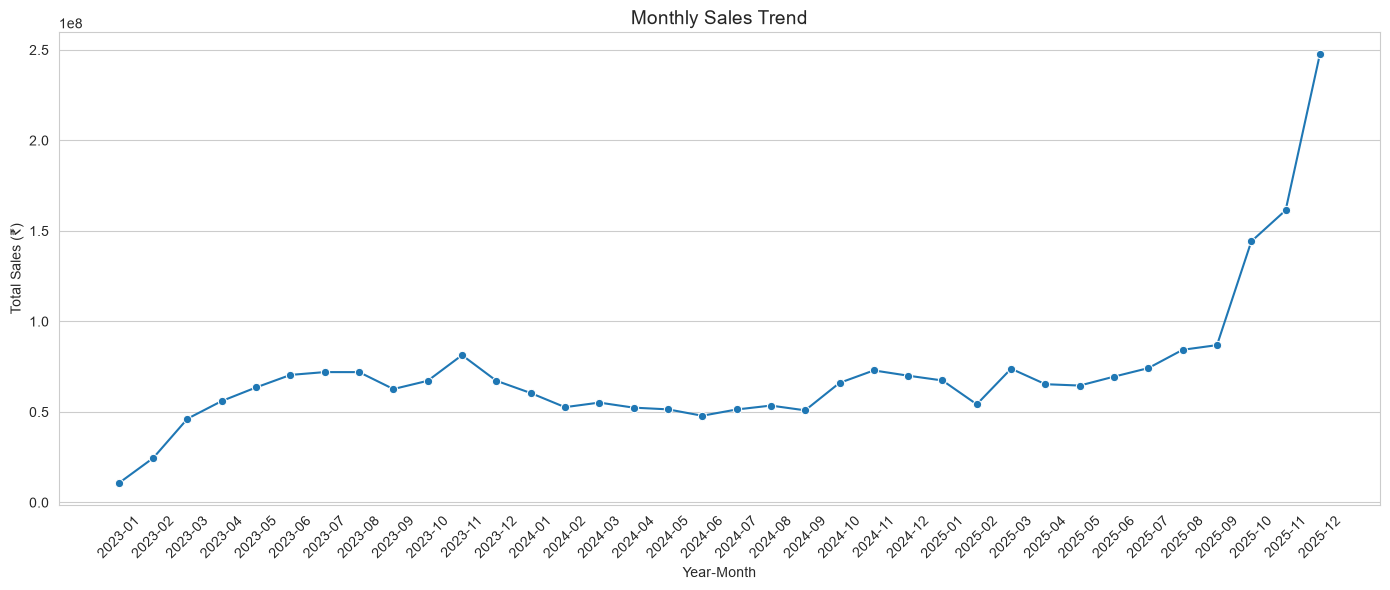

In [7]:
# 4. Sales Trend Over Time

print("\n" + "="*60)
print("SALES TREND OVER TIME")
print("="*60)

# Monthly Sales
monthly_sales = orders.groupby(['order_year', 'order_month'])['final_amount'].sum().reset_index()
monthly_sales['year_month'] = monthly_sales['order_year'].astype(str) + "-" + monthly_sales['order_month'].astype(str).str.zfill(2)

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_sales, x='year_month', y='final_amount', marker='o')
plt.title("Monthly Sales Trend", fontsize=14)
plt.xlabel("Year-Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(False, axis ='x')
plt.show()


SALES BY CATEGORY
                  category  item_revenue      profit  quantity
6              Electronics 1223618824.25  8450905.95     59068
0               Appliances  405233265.45 15743436.40     35842
12          Home & Kitchen  158075531.70 28392024.89     60205
9                Furniture  147011493.10 14348527.85      8118
7                  Fashion  139393560.30 46192014.22     98750
8                 Footwear   82603494.90 24298429.50     32501
3                     Bags   55912111.45 15984391.42     29948
11       Health & Wellness   31824329.15  6957754.85     36095
18                  Sports   26524050.15  5945316.96     13269
20                    Toys   24341259.45  5302530.64     28551
4                   Beauty   23365380.30  6190802.66     23387
21                 Watches   22006410.20  4232577.11      5019
14     Musical Instruments   20959349.00  2571868.11      4108
5                    Books   20036882.15  1917841.15     30396
10                 Grocery   1847793

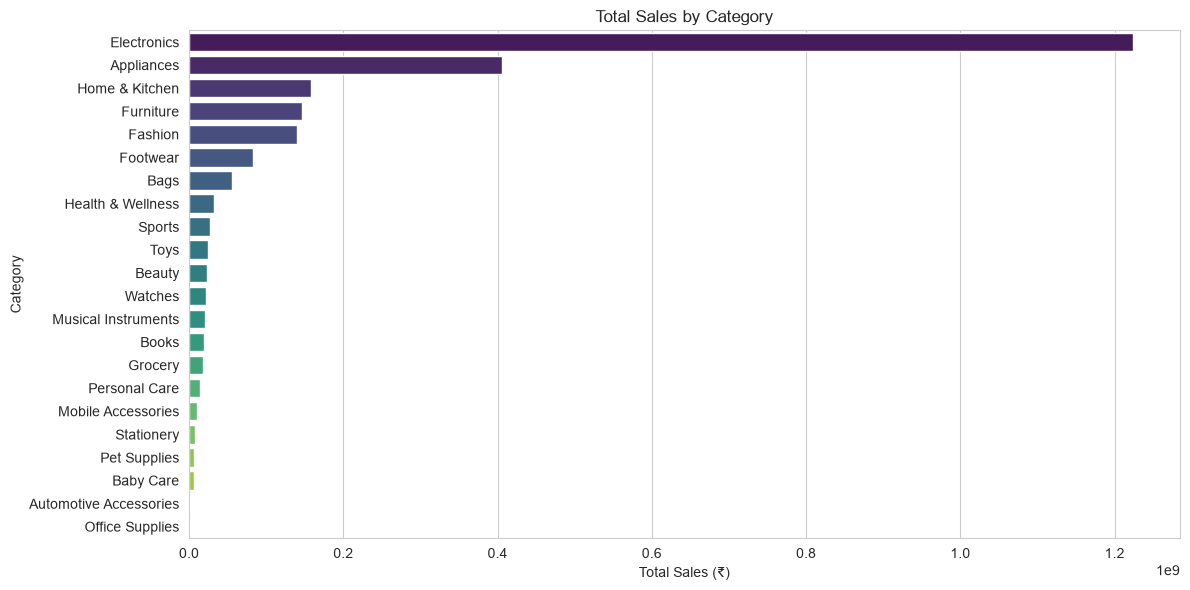

In [9]:
# 5. Sales by Category

print("\n" + "="*60)
print("SALES BY CATEGORY")
print("="*60)

category_sales = master.groupby('category').agg({
    'item_revenue': 'sum',
    'profit': 'sum',
    'quantity': 'sum'
}).reset_index().sort_values('item_revenue', ascending=False)

print(category_sales)

plt.figure(figsize=(12, 6))
sns.barplot(data=category_sales, x='item_revenue', y='category', palette='viridis',hue = 'category')
plt.title("Total Sales by Category")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


TOP 10 PRODUCTS BY SALES
product_name
Chaudhry, Advanced Smartwatche           520702863.25
Mistry, Basic Large Appliance            108975191.40
Gandhi-Lanka Ultra Storage & Container    81412219.20
Kala-Vaidya Deluxe Laptop                 72035300.40
Boase, Ultra Air Conditioner              63941248.35
Choudhury, Ultra Laptop                   61778685.90
Shanker-Dhar Signature Headphone          57085934.20
Gola Essential Fans & Cooler              52528883.55
Handa Advanced Laptop                     50817089.40
Mody-Kari Basic Smartphone                49101814.50
Name: item_revenue, dtype: float64


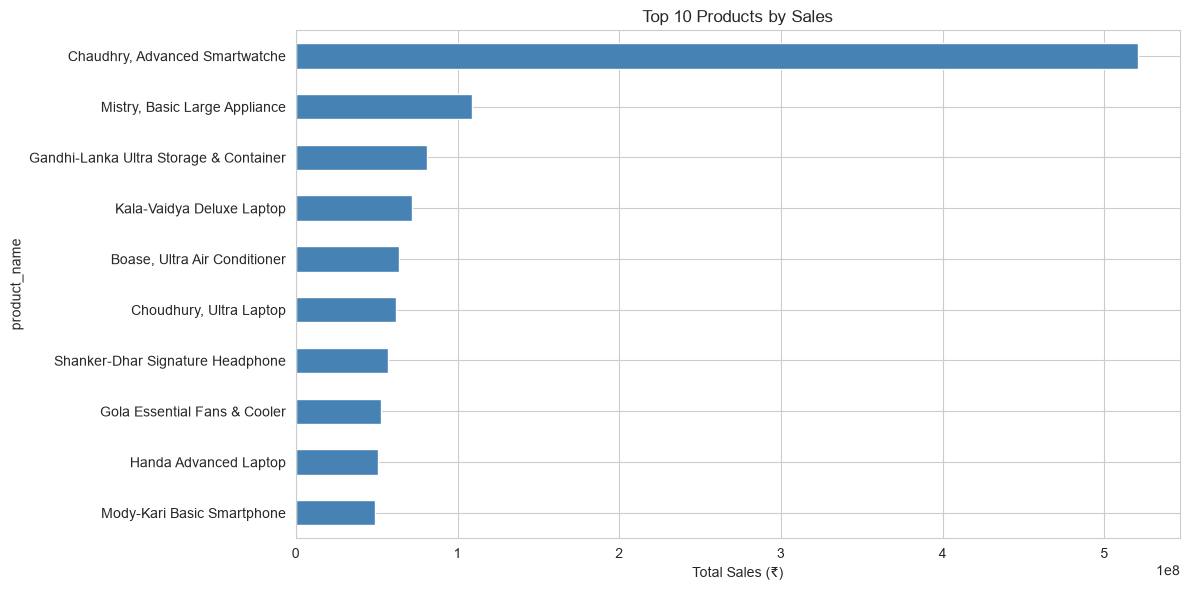

In [10]:
# 6. Top 10 Products by Sales

print("\n" + "="*60)
print("TOP 10 PRODUCTS BY SALES")
print("="*60)

top_products = master.groupby('product_name')['item_revenue'].sum().sort_values(ascending=False).head(10)
print(top_products)

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind='barh', color='steelblue')
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales (₹)")
plt.tight_layout()
plt.show()


SALES BY STATE
state
Maharashtra      342685310.95
Uttar Pradesh    268423443.85
Gujarat          259600880.55
Karnataka        193248100.35
Tamil Nadu       185416634.20
Telangana        178396746.20
Haryana          151126765.80
West Bengal      138750535.05
Kerala           124421083.10
Andhra Pradesh   119229776.30
Madhya Pradesh   111780671.70
Rajasthan        110852070.30
Delhi            110761866.95
Punjab           110516101.50
Bihar             44688987.55
Name: item_revenue, dtype: float64


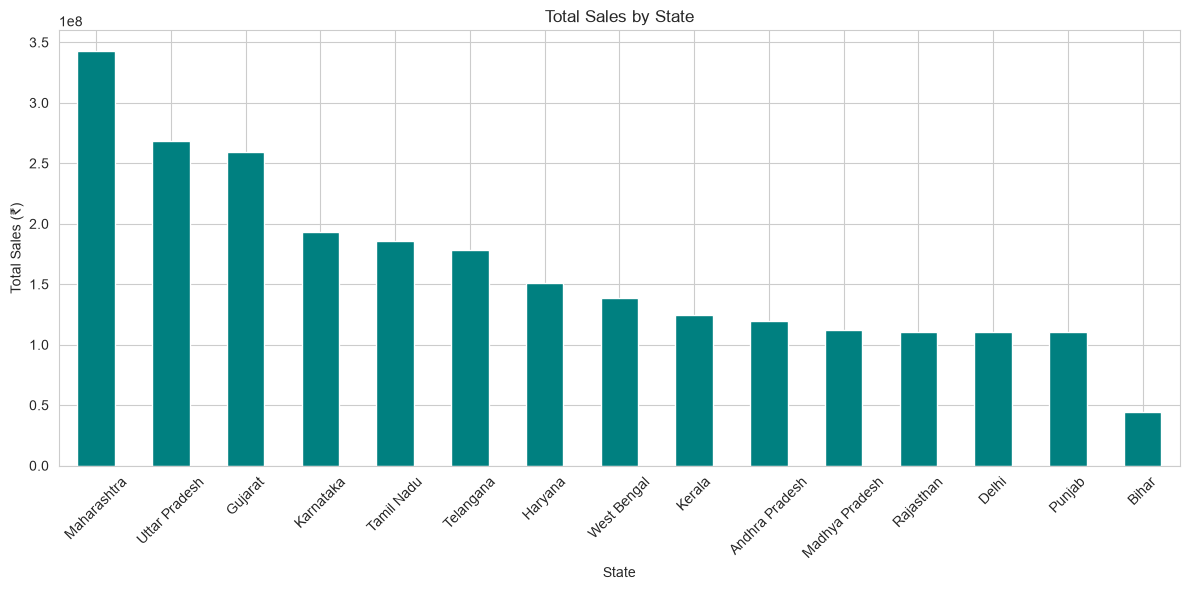

In [11]:
# 7. Sales by State

print("\n" + "="*60)
print("SALES BY STATE")
print("="*60)

state_sales = master.groupby('state')['item_revenue'].sum().sort_values(ascending=False)

print(state_sales)

plt.figure(figsize=(12, 6))
state_sales.plot(kind='bar', color='teal')
plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


PROFIT BY CATEGORY


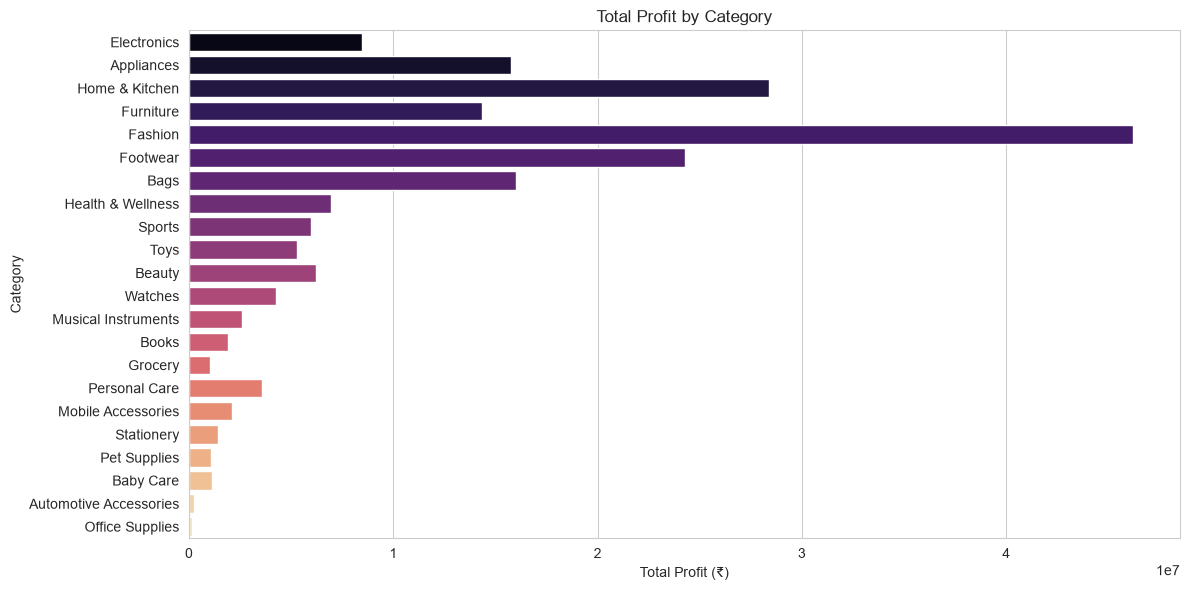

In [13]:
# 8. Profit Analysis by Category

print("\n" + "="*60)
print("PROFIT BY CATEGORY")
print("="*60)

plt.figure(figsize=(12, 6))
sns.barplot(data=category_sales, x='profit', y='category', palette='magma', hue='category')
plt.title("Total Profit by Category")
plt.xlabel("Total Profit (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


ORDER STATUS DISTRIBUTION
order_status
Delivered     80679
Cancelled      8073
Returned       6681
Failed         2880
Processing     1687
Name: count, dtype: int64


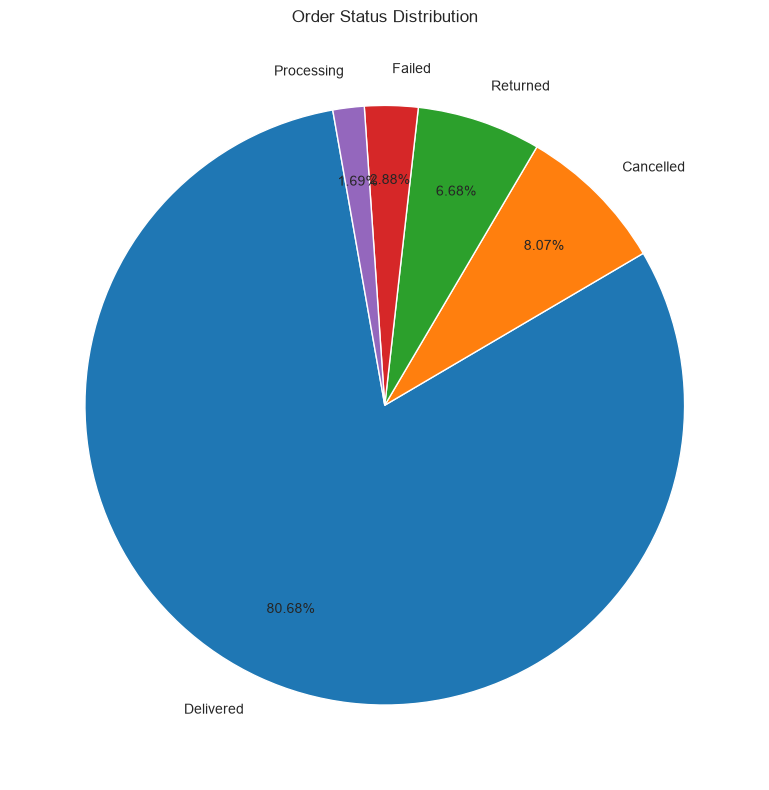

In [19]:
# 9. Order Status Distribution

print("\n" + "="*60)
print("ORDER STATUS DISTRIBUTION")
print("="*60)

status_counts = orders['order_status'].value_counts()
print(status_counts)

plt.figure(figsize=(10, 8))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.2f%%', startangle=100, pctdistance=0.75,
    labeldistance=1.12,
    textprops={'fontsize': 10})
plt.title("Order Status Distribution")
plt.tight_layout()
plt.show()


WEEKEND VS WEEKDAY SALES
Weekday   1719852083.48
Weekend    852740285.09
Name: final_amount, dtype: float64


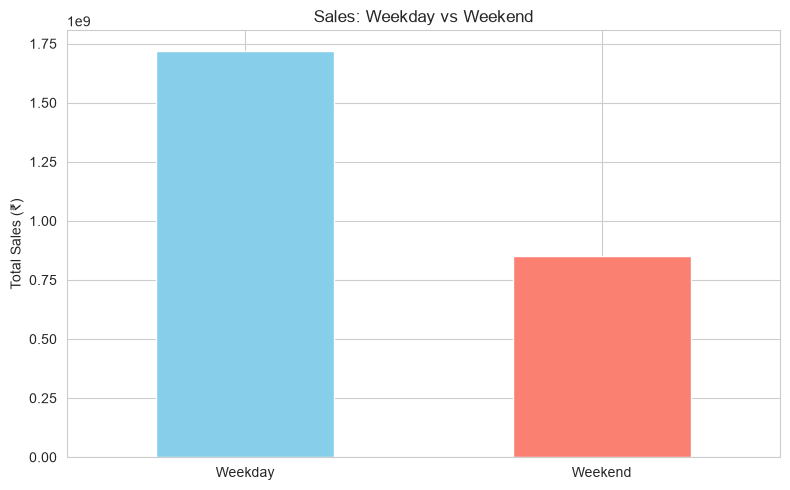

In [20]:
# 10. Weekend vs Weekday Sales

print("\n" + "="*60)
print("WEEKEND VS WEEKDAY SALES")
print("="*60)

weekend_sales = orders.groupby('is_weekend')['final_amount'].sum()
weekend_sales.index = ['Weekday', 'Weekend']
print(weekend_sales)

plt.figure(figsize=(8, 5))
weekend_sales.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title("Sales: Weekday vs Weekend")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### KEY INSIGHTS FROM EDA & Sales Analysis

1. Sales trend shows clear patterns over months (check for seasonality).
2. Some categories contribute significantly higher revenue than others.
3. A few products drive a large portion of total sales.
4. Certain states generate much higher sales (geographic concentration).
5. Profitability is not always aligned with highest sales categories.
6. Order status distribution helps understand cancellation/return rates.
7. Weekend vs Weekday sales show customer buying behavior.